# Poisson Statistics for Cluster Detection

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 2 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

In Chapter 2 we built the theory of probabilistic reasoning, and we saw how prior knowledge and observed data combine into a posterior belief. This tutorial applies these ideas to a practical problem, the detection of stellar clusters from the spatial pattern of stars.

Stars in our Galaxy follow a smooth distribution, set by the gravitational potential and the formation history of the Milky Way. Against this background, a stellar cluster is a local overdensity, a region where the density of stars is far above the expectation. This is a good setting to learn how probability theory measures deviations from the expectation for a random field and finds physically meaningful structures.

Such overdensities connect to basic questions in astrophysics. Consider the search for intermediate-mass black holes (IMBHs) in the Milky Way halo, which lie between stellar-mass and supermassive black holes. Theory predicts that IMBHs should keep bound clusters of stars, which create detectable overdensities. [Greene et al. (2021)](https://ui.adsabs.harvard.edu/abs/2021ApJ...917...17G/abstract) searched for stellar overdensities that could indicate such black holes.

We compare the observed star counts with the expectation from the background, and so we find candidate clusters. When we find no overdensity, the same comparison limits the number of IMBHs. Each one would leave a star count that is very unlikely under the background.

The same ideas apply beyond stellar astronomy. Examples are galaxy clusters in large-scale structure surveys and excess high-energy particle events that could signal dark matter annihilation. In each case, we want to tell real physical structures from random fluctuations of the background.

A quantitative approach has an advantage over visual inspection, which becomes difficult in high-dimensional spaces. We replace the judgment of the eye with a number, the likelihood of the star count at each position under the background model. This lets us make objective statements about the presence or absence of clusters.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Python programming with NumPy arrays and matplotlib plots
- Probability theory, in particular probability distributions and discrete distributions
- Basic knowledge of random variables, expectation values and independence

### Learning Objectives

After this tutorial you can do the following.

- Model the star counts of a field with the Poisson distribution
- Check with joint and conditional distributions that the counts of two regions are independent
- Find overdensities as counts that are very unlikely under the background model
- Estimate the expected count with maximum likelihood estimation
- Handle edge effects and spatial correlations in a two-dimensional point pattern

## Setup

We begin by importing the libraries, setting the plot style and fixing the random seed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 10]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Fix the random seed
np.random.seed(42)

%matplotlib inline

## Modeling the Stellar Background Field

We begin with the simplest case, a uniform random distribution of stars in a two-dimensional field. This idealization is our null hypothesis, the expected distribution in the absence of clusters. We model it as a spatial Poisson process. The number of stars in any region then follows the Poisson distribution of Chapter 2 (Section 2.3).

This model has three assumptions.

1. **Spatial homogeneity.** The background density $\rho$ is the same everywhere in the field.
2. **Spatial stationarity.** The statistical properties do not change under a translation.
3. **Complete spatial randomness.** A star at one location does not change the probability of finding stars at other locations.

With these assumptions, the probability that the number of stars $X$ in a region of area $A$ equals $k$ is

$$P(X = k|\lambda) = \frac{\lambda^k e^{-\lambda}}{k!},$$

where $\lambda = \rho A$ is the expected number of stars in the region.

The uniform model is an idealization. In real astronomical applications, the stellar density $\rho(l,b)$ changes with the Galactic coordinates. The causes are the structure of the Galactic disk, the spiral arms, differential extinction and the selection effects of the observations. The uniform model is still our starting point, and we can extend the method to realistic densities with coordinate transformations or local density estimates.

We first simulate a field of 10,000 stars and plot it.

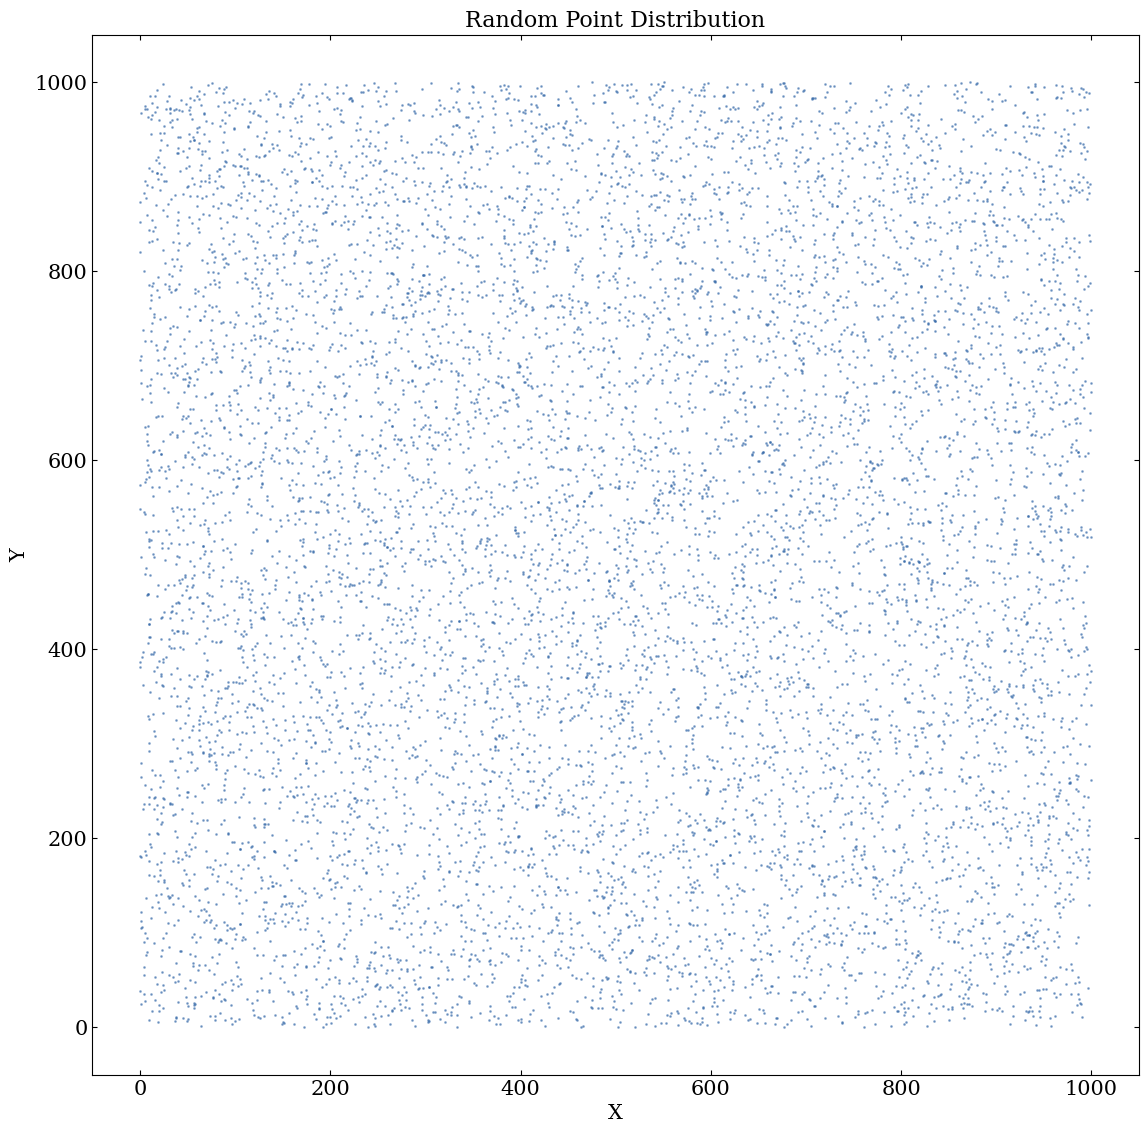

In [2]:
def generate_random_field(n_points, field_size=(1000, 1000)):
    """Generate n_points random positions in a 2D field."""

    # Uniform random x and y positions
    x = np.random.uniform(0, field_size[0], n_points)
    y = np.random.uniform(0, field_size[1], n_points)
    return np.column_stack((x, y))  # One row (x, y) per point

# Generate 10,000 random points
points = generate_random_field(10000)

# Plot the points
plt.figure(figsize=(13.5, 13.5))
plt.scatter(points[:,0], points[:,1], s=1, alpha=0.5)

# Title and axis labels
plt.title('Random Point Distribution')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

## Random Variables and Counting Statistics

The difference between deterministic and random variables is clear in a stellar field. Consider the average stellar density in a region of our simulated field. It is set by the underlying properties of the stellar distribution, so it is a deterministic variable. The actual number of stars $X$ that we observe in a region is a random variable (Section 2.1). It fluctuates around the expected value, because the star positions are random.

This is like many astronomical measurements. The true orbital period of a planet is deterministic, but our measurements of it contain random uncertainties. In the same way, the true stellar density is fixed, but our counts vary randomly. For counting observations, this randomness has a specific mathematical form.

We count discrete objects such as stars. If each detection is independent and the average rate is constant, the counts follow the Poisson distribution above. Here $\lambda = \rho A$ is the expected number of stars for the background density $\rho$ and the area $A$ of the counting region. The Poisson distribution arises when three conditions hold.

1. The events occur independently.
2. The average rate is constant over the observation interval.
3. Two events cannot occur at exactly the same location.

To see how the expected density relates to the observed counts, we analyze the distribution of stars in circular annuli. An annulus is the region between two radii, and the first one starts at radius 0. By dividing the analysis region into concentric rings, we see how the counts change with the distance from a center. We draw a new field and mark two annuli around a center.

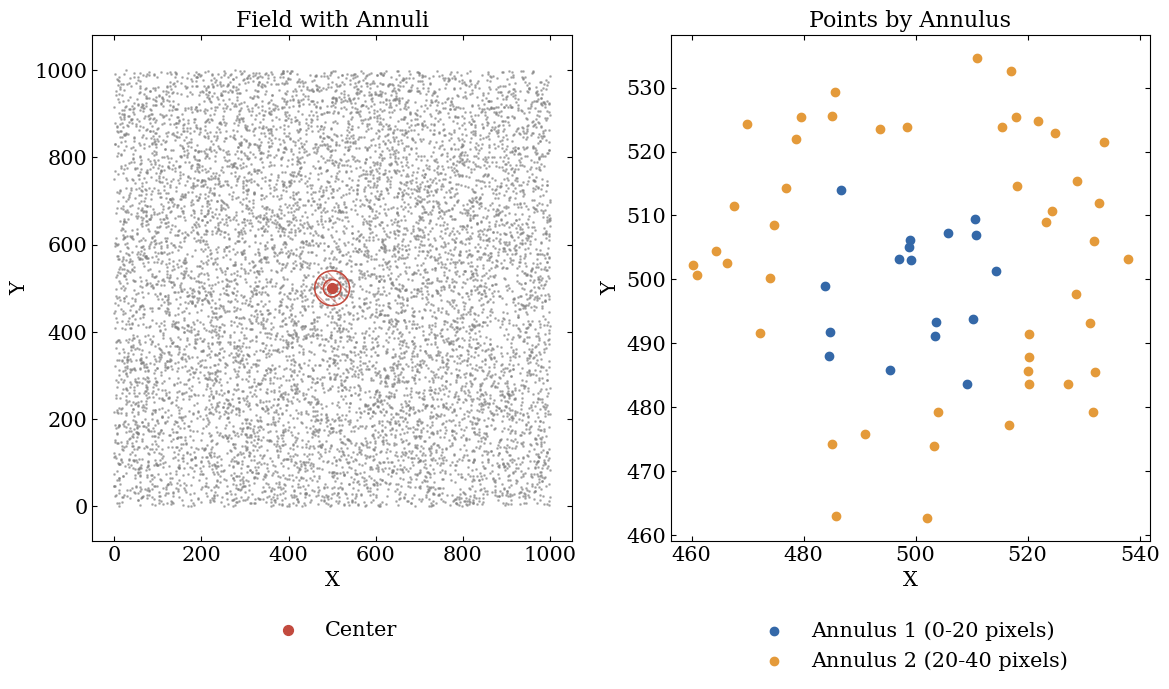

In [3]:
# Draw a second field and plot it with the annuli
points = generate_random_field(10000)
center = [500, 500]

plt.figure(figsize=(12, 7.2))

# Radii of the annuli in pixels
inner_radius = 0
middle_radius = 20
outer_radius = 40

# Left panel, the field with the two annuli
plt.subplot(1, 2, 1)
plt.scatter(points[:,0], points[:,1], s=1, alpha=0.5, color='gray')

# First annulus, 0 to 20 pixels, a ring patch with forward hatching
wedge1 = matplotlib.patches.Wedge(center, middle_radius, 0, 360,
                                width=middle_radius-inner_radius,
                                fill=False, hatch='///',
                                color='C3', alpha=0.5)
plt.gca().add_patch(wedge1)

# Second annulus, 20 to 40 pixels, a ring patch with backward hatching
wedge2 = matplotlib.patches.Wedge(center, outer_radius, 0, 360,
                                width=outer_radius-middle_radius,
                                fill=False, hatch='\\\\\\',
                                color='C3', alpha=0.5)
plt.gca().add_patch(wedge2)

# Circle boundaries
for radius in [inner_radius, middle_radius, outer_radius]:
    circle = plt.Circle(center, radius, fill=False, color='C3')
    plt.gca().add_artist(circle)

plt.scatter(center[0], center[1], color='C3', s=50, label='Center')

# Equal axes, title, labels and legend
plt.axis('equal')
plt.title('Field with Annuli')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12))

# Right panel, the points of each annulus
plt.subplot(1, 2, 2)

# Distance of each point from the center
distances = np.sqrt(np.sum((points - center)**2, axis=1))

# First annulus, 0 to 20 pixels, selected with a mask
mask = (distances >= inner_radius) & (distances < middle_radius)
points_in_annulus = points[mask]
plt.scatter(points_in_annulus[:,0], points_in_annulus[:,1],
            label=f'Annulus 1 ({inner_radius}-{middle_radius} pixels)')

# Second annulus, 20 to 40 pixels, selected with a mask
mask = (distances >= middle_radius) & (distances < outer_radius)
points_in_annulus = points[mask]
plt.scatter(points_in_annulus[:,0], points_in_annulus[:,1],
            label=f'Annulus 2 ({middle_radius}-{outer_radius} pixels)')

# Title, labels and legend
plt.title('Points by Annulus')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12))

# Avoid overlapping labels
plt.tight_layout()
plt.show()


This visualization shows how the random variable $X$, the number of stars, relates to the deterministic background density in different regions. The annular geometry lets us sample different radial distances from a given center. The second annulus covers a larger area, so it holds more stars.

For a uniform random field, the expected number of stars $\lambda$ in an annulus scales with its area. For an inner radius $r_1$ and an outer radius $r_2$, the area is

$$A = \pi(r_2^2 - r_1^2).$$

With a uniform background density $\rho$ (stars per unit area), the expected count is

$$\lambda = \rho A = \rho\pi(r_2^2 - r_1^2).$$

We generated 10,000 stars in a field of 1000 by 1000 pixels, so the background density is $\rho = 0.01$ stars per pixel$^2$. This known density lets us predict the expected counts in each annulus and check that the observations follow the theoretical Poisson distribution.

For this check, we use each star in the field as a center and count its neighbors in both annuli. This gives many samples, and it prepares us for cluster detection. The stars of a cluster will show deviations from the Poisson expectation in their neighbor counts.

In [4]:
# Radii of the annuli
radii = np.array([0, 20, 40])

# Distances between all pairs of stars, with periodic boundary conditions
field_size = 1000  # Size of the field in pixels
distances = np.zeros((len(points), len(points)))
for i in range(len(points)):
    dx = points[:, 0] - points[i, 0]
    dy = points[:, 1] - points[i, 1]

    # Wrap the separations at the boundaries
    # A separation above half the field is shorter the other way round
    dx = np.where(dx > field_size/2, dx - field_size, dx)
    dx = np.where(dx < -field_size/2, dx + field_size, dx)

    # The same for y
    dy = np.where(dy > field_size/2, dy - field_size, dy)
    dy = np.where(dy < -field_size/2, dy + field_size, dy)

    distances[i] = np.sqrt(dx**2 + dy**2)

# A star is not its own neighbor, so its distance to itself is infinite
np.fill_diagonal(distances, np.inf)

# Count the neighbors of each star in each annulus
all_counts = []

for i in range(len(points)):
    counts = np.zeros(len(radii)-1)  # Counts for each annulus

    for j in range(len(radii)-1):
        r_inner = radii[j]
        r_outer = radii[j+1]

        # Mask of the stars in this annulus
        mask = (distances[i] >= r_inner) & (distances[i] < r_outer)
        counts[j] = np.sum(mask)

    all_counts.append(counts)

# Convert to a numpy array
all_counts = np.array(all_counts)

We compare the neighbor counts of each annulus with a Poisson distribution in histograms.

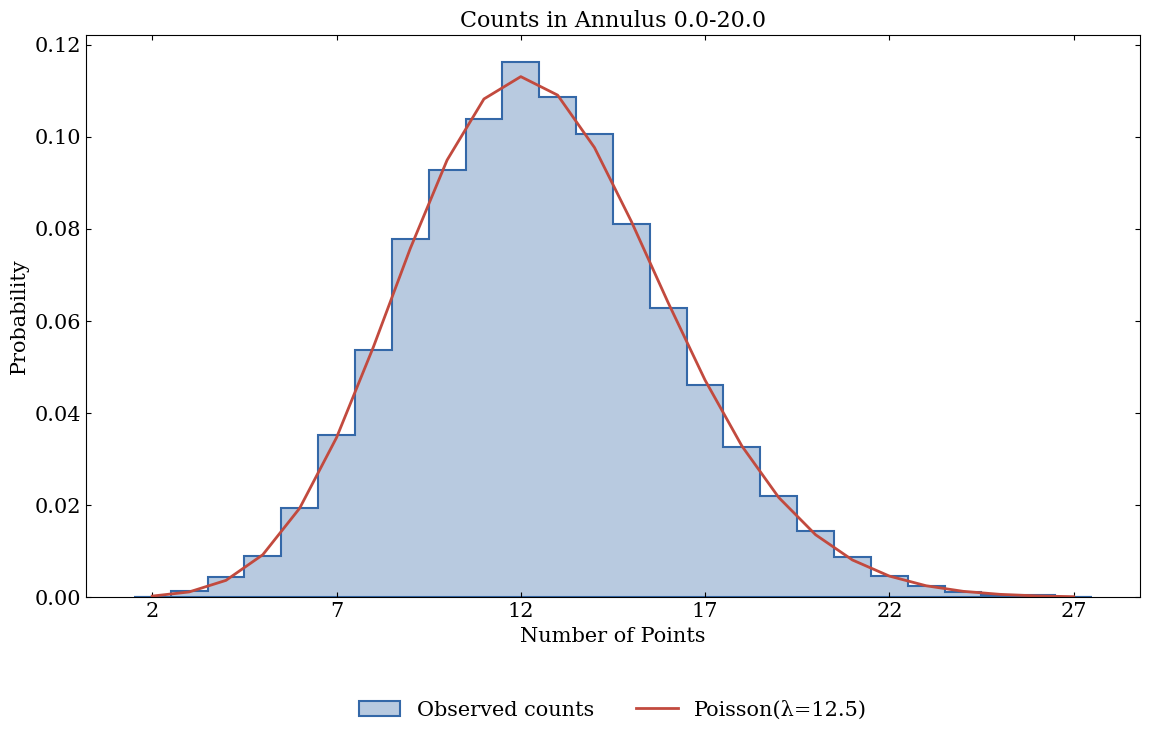

Expected λ from area = 12.57
Observed mean count = 12.54
Observed variance = 12.56


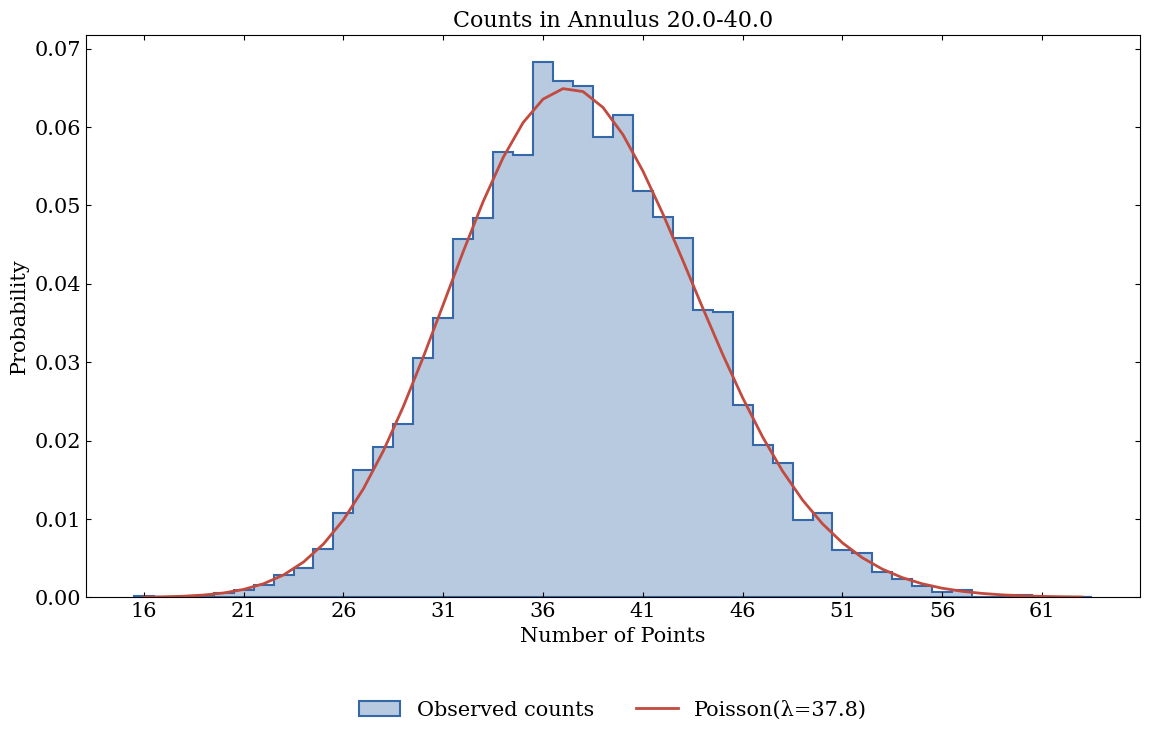

Expected λ from area = 37.70
Observed mean count = 37.78
Observed variance = 37.03


In [5]:
def poisson_logpmf(k, lam):
    """Return the logarithm of the Poisson probability of the count k for the mean lam."""
    k = np.asarray(k).astype(int)

    # Logarithm of k!, from the cumulative sum of the logarithms of 1 to k
    log_factorial = np.concatenate([[0], np.cumsum(np.log(np.arange(1, k.max() + 1)))])[k]
    return k * np.log(lam) - lam - log_factorial

def poisson_pmf(k, lam):
    """Return the Poisson probability of the count k for the mean lam."""
    return np.exp(poisson_logpmf(k, lam))

# Compare the counts of each annulus with a Poisson distribution
for i in range(2):
    counts = all_counts[:,i]  # counts of this annulus
    r_inner = radii[i]
    r_outer = radii[i+1]
    rho = 0.01  # density of the points per pixel squared

    # Expected count from the geometry
    area = np.pi * (r_outer**2 - r_inner**2)
    lambda_expected = rho * area
    lambda_observed = np.mean(counts)

    plt.figure(figsize=(13.6, 7.3))

    # Integer bins that fully span the data
    bin_edges = np.arange(min(counts)-0.5, max(counts)+1.5, 1)

    # Histogram of the counts
    plt.hist(counts, bins=bin_edges, density=True, label='Observed counts',
             histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)

    # Poisson probabilities at the integers, with the observed mean
    x = np.arange(min(counts), max(counts)+1)
    poisson = poisson_pmf(x, lambda_observed)
    plt.plot(x, poisson, '-', color='C3', linewidth=2,
            label=f'Poisson(λ={lambda_observed:.1f})')

    plt.title(f'Counts in Annulus {r_inner:.1f}-{r_outer:.1f}')
    plt.xlabel('Number of Points')
    plt.ylabel('Probability')
    plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

    # Show every fifth tick
    plt.xticks(np.arange(min(counts), max(counts)+1, 5))

    plt.show()

    # Print the expected and observed values
    print(f"Expected λ from area = {lambda_expected:.2f}")
    print(f"Observed mean count = {lambda_observed:.2f}")
    print(f"Observed variance = {np.var(counts):.2f}")

Our implementation uses several techniques that deserve a comment. First, we use every star in the field as a center and count its neighbors, without the star itself. This gives 10,000 overlapping measurements of the local density distribution, far more than a single center gives. The Poisson distribution is then well characterized.

Second, we use periodic boundary conditions, so the field is a torus. Without them, stars near the edges would have fewer neighbors than stars in the interior, which gives a wrong density. When the x-distance between two stars is larger than half the field size, the shorter path wraps around the boundary. The same holds for the y-distance. The wrap connects the left edge to the right edge and the top to the bottom, so every star has a complete neighborhood. We use it for simplicity, while real astronomical applications typically exclude the edge regions or apply window functions.

The histograms confirm our expectation. Each annulus shows a count distribution that matches the Poisson distribution with $\lambda$ equal to the observed mean. The observed mean is also close to the expected $\lambda$ from the geometry. The variance is close to the mean, as it is for a Poisson distribution. This agreement confirms both our uniform field and our understanding of how a Poisson process appears in a spatial point pattern.

## Joint and Conditional Distributions in Point Counts

The distributions that we examined for the individual annuli are marginal distributions. They describe the counts in a single region and ignore the relation between regions. We get the marginal distribution of $X_1$, the count in the first annulus, from the joint distribution. We sum over all values of $X_2$, the count in the second annulus (Section 2.5)

$$p(X_1) = \sum_{X_2} p(X_1,X_2),$$

where $p(X_1,X_2)$ is the joint probability (Section 2.4) of $X_1$ stars in the first annulus and $X_2$ stars in the second.

Joint distributions matter for cluster detection. Marginal distributions describe the overall density field, and joint distributions show spatial correlations. In a truly random field, we expect no correlation between the counts of non-overlapping regions. A cluster, however, creates a positive correlation, because a high count in one annulus predicts a high count in the nearby annulus.

The joint distribution $p(X_1,X_2)$ of our two annuli describes this relation. We estimate it with a two-dimensional histogram of the observed pairs of counts. Each star gives one pair $(X_1, X_2)$. Here $X_1$ counts the neighbors within 20 pixels, and $X_2$ counts those between 20 and 40 pixels.

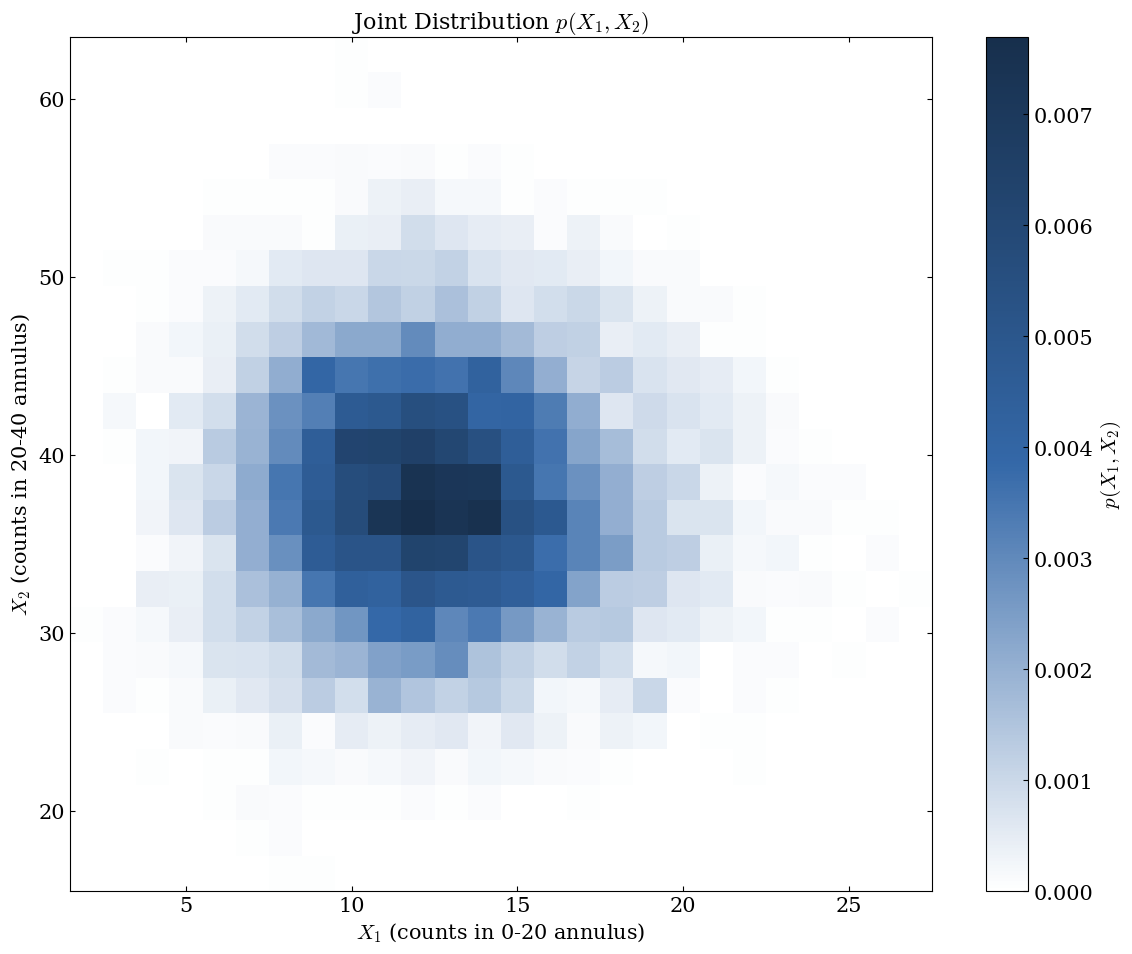

In [6]:
plt.figure(figsize=(13.9, 11.1))

# Two-dimensional histogram of the counts
# Bin edges at half-integers hold whole integer counts (width 1 in N1, width 2 in N2)
bins_1 = np.arange(all_counts[:,0].min() - 0.5, all_counts[:,0].max() + 1.5, 1)
bins_2 = np.arange(all_counts[:,1].min() - 0.5, all_counts[:,1].max() + 2.5, 2)
h = plt.hist2d(all_counts[:,0], all_counts[:,1], bins=[bins_1, bins_2], density=True, cmap='book_blue')
plt.colorbar(h[3], label='$p(X_1,X_2)$')

plt.xlabel('$X_1$ (counts in 0-20 annulus)')
plt.ylabel('$X_2$ (counts in 20-40 annulus)')
plt.title('Joint Distribution $p(X_1,X_2)$')
plt.show()


The joint distribution shows the relation between the counts of our two annuli. For a truly random point process, we expect no correlation structure. The count in one annulus should not predict the count in the other, and the plot shows a single blob without a tilt.

To examine this independence more carefully, we look at the conditional distribution $p(X_2|X_1)$. It is the distribution of the counts in the outer annulus for a given count in the inner annulus. If the annuli are statistically independent, then

$$p(X_2|X_1) = p(X_2).$$

This equality says that knowing $X_1$ gives no information about $X_2$. We can test it by selecting the stars with a specific $X_1$ and looking at their $X_2$ distribution. Because the counts are discrete, we can choose exact integer values of $X_1$.

By the product rule (Section 2.5),

$$p(X_1,X_2) = p(X_2|X_1)p(X_1).$$

When the counts are independent, this becomes

$$p(X_1,X_2) = p(X_2)p(X_1).$$

This factorization has a practical consequence. We can analyze each annulus separately without losing information about their joint behavior. This reduces the dimension of the problem. It helps when we extend the analysis to many annuli, or when the data are few and a high-dimensional joint distribution is hard to estimate. Below we compare the $X_2$ distributions for two values of $X_1$.

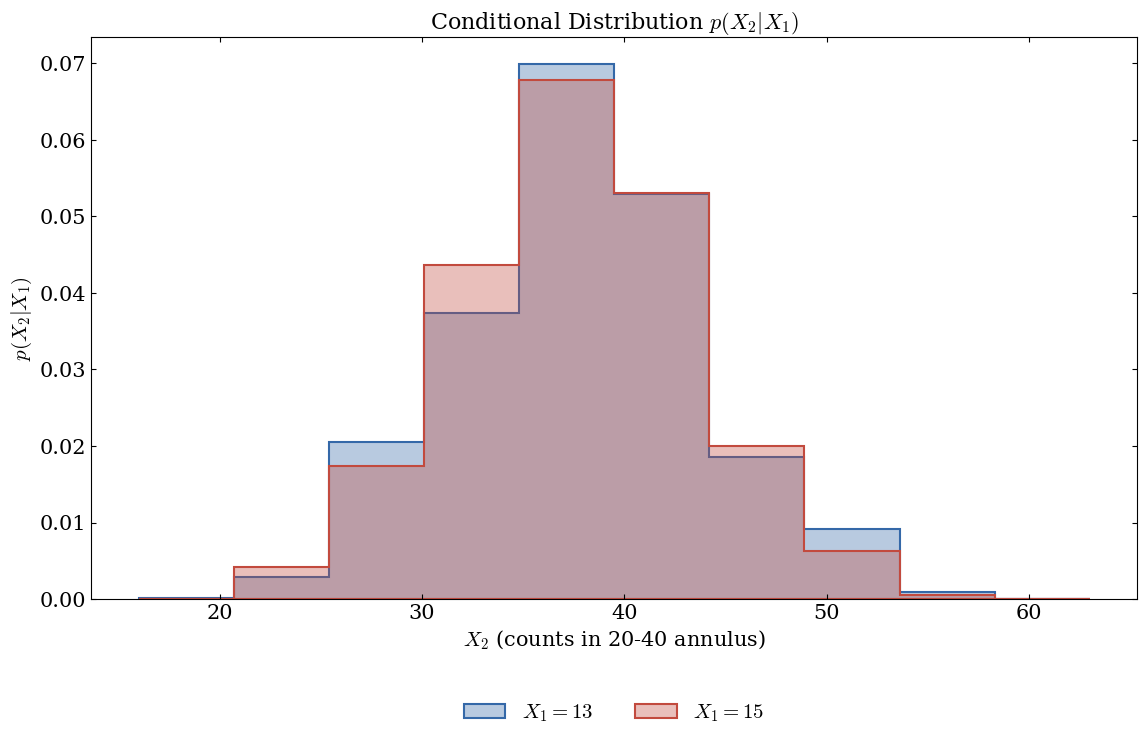

In [7]:
# Two specific N1 values to condition on
N1_values = [13, 15]

plt.figure(figsize=(13.5, 7.3))
colors = ['C0', 'C3']

# The same bins for both histograms
bins = np.linspace(all_counts[:,1].min(), all_counts[:,1].max(), 11)

for N1, color in zip(N1_values, colors):
    # Select the stars where N1 matches the chosen value exactly
    matches = all_counts[all_counts[:,0] == N1]
    plt.hist(matches[:,1], bins=bins, density=True, label=f'$X_1 = {N1}$',
             histtype='stepfilled', facecolor=(color, 0.35), edgecolor=color, linewidth=1.5)

plt.xlabel('$X_2$ (counts in 20-40 annulus)')
plt.ylabel('$p(X_2|X_1)$')
plt.title('Conditional Distribution $p(X_2|X_1)$')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()


The conditional distributions $p(X_2|X_1=13)$ and $p(X_2|X_1=15)$ are similar. This is empirical evidence for statistical independence. Despite the different $X_1$, the distribution of $X_2$ stays the same. A truly random point process behaves this way, because the number of stars in one annulus does not predict the number in a non-overlapping annulus.

Independence is the basis of our cluster detection strategy. In a random field, a high neighbor count around a star is a statistical fluctuation that does not extend to larger radii. A real cluster instead creates correlated high counts in several annuli around the same star. By measuring the deviations from independence, we can tell random fluctuations from true overdensities.

Independence also makes the analysis simpler. The joint distribution over many annuli is high-dimensional and hard to estimate from finite data. If independence holds, it factors into a product of simple marginal distributions

$$p(X_1, X_2, \dots, X_k) = p(X_1)p(X_2)\cdots p(X_k).$$

This reduces the number of parameters to estimate from exponential in $k$ to linear in $k$. The analysis then stays manageable for many annuli. The simplification applies only to our null hypothesis of a random field, and to detect clusters we must find where the independence breaks.

## Detecting Clusters Through Likelihood Analysis

We have shown that our background field follows Poisson statistics, with independent counts in non-overlapping regions. We can now build a method for cluster detection. A stellar cluster is a region where the local neighbor count $X$ is far above the Poisson expectation for a random field.

For each star in our field, we count the neighbors within a given radius. We compare the count with our null hypothesis, the expected distribution in a random field. The stars of a cluster have higher neighbor counts, so we can tell them from the background stars.

To test the method, we add simulated clusters to our random field. We model each cluster as a two-dimensional Gaussian distribution of stars. It is simple, and it is a reasonable approximation of many real stellar clusters. The cluster centers are placed uniformly at random in the field, and the position of each member star follows

$$\mathbf{x} \sim \mathcal{N}(\boldsymbol{\mu}_c, \sigma^2\mathrm{Id}_2),$$

where $\mathbf{x} = (x, y)$ is the position of a member star and $\boldsymbol{\mu}_c$ is the cluster center. Here $\mathrm{Id}_2$ is the $2 \times 2$ identity matrix, and $\sigma$ sets the spatial extent of the cluster. We choose $\sigma = 20$ pixels for the first cluster (200 stars) and $\sigma = 15$ pixels for the second (100 stars). Both are close to the radius of our neighbor count.

In [8]:
def generate_cluster(n_points, center, sigma):
    """Generate n_points of a cluster with a 2D Gaussian distribution."""

    # Gaussian x and y positions around the center
    x = np.random.normal(center[0], sigma, n_points)
    y = np.random.normal(center[1], sigma, n_points)

    return np.column_stack((x, y))  # One row (x, y) per point

# Fix the random seed again
np.random.seed(42)

# Field parameters
L = 1000  # Field size in pixels

# Background stars
background_points = generate_random_field(10000)

# Generate the clusters
# First cluster, 200 stars, sigma = 20
center1 = np.random.uniform(0, L, 2)  # Random center
cluster1 = generate_cluster(200, center1, 20)

# Second cluster, 100 stars, sigma = 15
center2 = np.random.uniform(0, L, 2)  # Random center
cluster2 = generate_cluster(100, center2, 15)

# Combine the background and the clusters
field_with_clusters = np.vstack((background_points, cluster1, cluster2))

We plot the field with a zoom on the first cluster, and we print the cluster parameters.

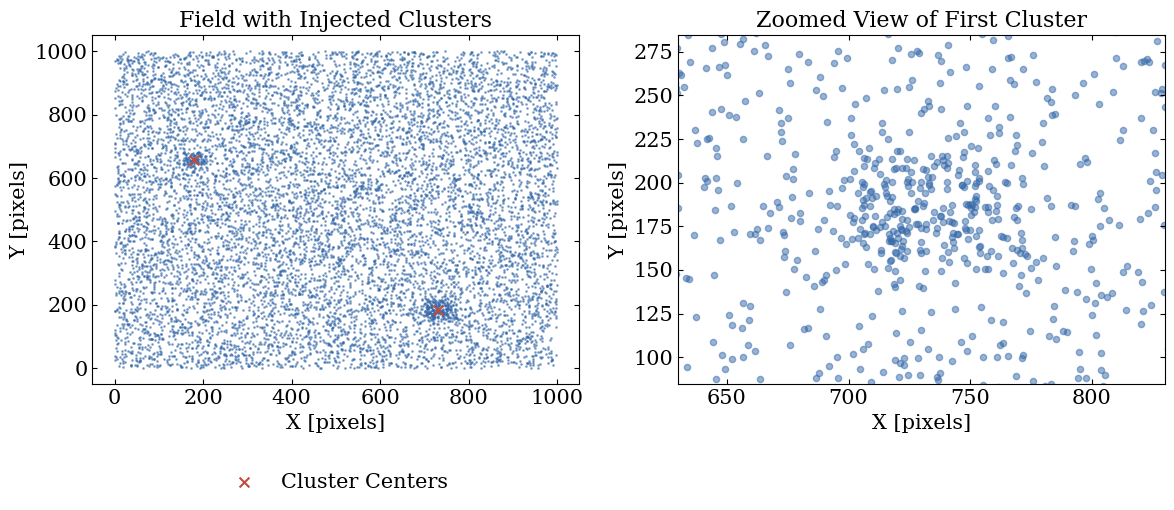

First cluster = 200 points at (730.0, 184.5)
Second cluster = 100 points at (179.0, 657.2)


In [9]:
# Plot the field
plt.figure(figsize=(12, 5.5))

# Left panel, the full field
plt.subplot(1, 2, 1)
plt.scatter(field_with_clusters[:,0], field_with_clusters[:,1],
           s=1, alpha=0.5)

# Title and axis labels
plt.title('Field with Injected Clusters')
plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')

# Right panel, a zoom on the first cluster
plt.subplot(1, 2, 2)
margin = 100
plt.scatter(field_with_clusters[:,0], field_with_clusters[:,1],
           s=20, alpha=0.5)

# Zoom on the first cluster
plt.xlim(center1[0]-margin, center1[0]+margin)
plt.ylim(center1[1]-margin, center1[1]+margin)

# Title and axis labels
plt.title('Zoomed View of First Cluster')
plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')

# Mark the cluster centers in the left panel
plt.subplot(1, 2, 1)
plt.scatter([center1[0], center2[0]], [center1[1], center2[1]],
           color='C3', marker='x', s=50, label='Cluster Centers')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2))

plt.tight_layout()
plt.show()

# Print the cluster parameters
print(f"First cluster = {len(cluster1)} points at ({center1[0]:.1f}, {center1[1]:.1f})")
print(f"Second cluster = {len(cluster2)} points at ({center2[0]:.1f}, {center2[1]:.1f})")

## Likelihood Analysis

With the clusters in our field, we can develop a statistical method to detect them. For each star, we count the neighbors $X_1$ within a radius $r$ of 20 pixels. Under the null hypothesis of a random field, this count follows a Poisson distribution with the expected count $\lambda = \rho\pi r^2$ of the background stars. The probability of exactly $k$ neighbors is

$$P(X_1 = k|\lambda) = \frac{\lambda^k e^{-\lambda}}{k!}.$$

This probability is the likelihood $\mathcal{L}$ (Section 2.7) of observing exactly $k$ neighbors under our background model. It tells us how probable our observation is under the model. A low likelihood means that the observation is unlikely under the model assumptions.

The stars of a cluster have unusually high neighbor counts, so they have very low likelihoods under the background-only model. This makes sense, because finding many neighbors around a star is very improbable if the stars are distributed at random. Clusters produce neighbor counts that are incompatible with random placement.

The log-likelihood is more convenient

$$\ln \mathcal{L} = k\ln(\lambda) - \lambda - \ln(k!).$$

The logarithm keeps very small probabilities from rounding to zero on the computer, and it turns a product of probabilities into a sum. A more negative log-likelihood means a more improbable observation under the null hypothesis.

By calculating the log-likelihood over the whole field, we create a map that shows regions of unusually high density. Clusters appear as wells in this map, regions where the counts are so high that a random field would very rarely produce them. We now count the neighbors of every star in the new field and compare the background stars with the two clusters.

In [10]:
# Distances between all pairs of stars of the new field, with periodic boundary conditions
field_size = 1000  # Size of the field in pixels
distances = np.zeros((len(field_with_clusters), len(field_with_clusters)))
for i in range(len(field_with_clusters)):
    dx = field_with_clusters[:, 0] - field_with_clusters[i, 0]
    dy = field_with_clusters[:, 1] - field_with_clusters[i, 1]

    # Wrap the separations at the boundaries
    # A separation above half the field is shorter the other way round
    dx = np.where(dx > field_size/2, dx - field_size, dx)
    dx = np.where(dx < -field_size/2, dx + field_size, dx)

    # The same for y
    dy = np.where(dy > field_size/2, dy - field_size, dy)
    dy = np.where(dy < -field_size/2, dy + field_size, dy)

    distances[i] = np.sqrt(dx**2 + dy**2)

# A star is not its own neighbor, so its distance to itself is infinite
np.fill_diagonal(distances, np.inf)

# Radii of the annuli
radii = np.array([0, 20, 40])

# Count the neighbors of each star in each annulus
all_counts = []

for i in range(len(field_with_clusters)):
    counts = np.zeros(len(radii)-1)  # Counts for each annulus

    for j in range(len(radii)-1):
        r_inner = radii[j]
        r_outer = radii[j+1]

        # Mask of the stars in this annulus
        mask = (distances[i] >= r_inner) & (distances[i] < r_outer)
        counts[j] = np.sum(mask)

    all_counts.append(counts)

all_counts = np.array(all_counts)

# Separate the N1 counts of the background and the clusters
background_N1 = all_counts[:10000, 0]  # The first 10,000 stars are background
cluster1_N1 = all_counts[10000:10200, 0]  # The next 200 stars are cluster 1
cluster2_N1 = all_counts[10200:, 0]  # The last 100 stars are cluster 2

We plot the distributions of the neighbor count and of its log-likelihood for the background and the two clusters.

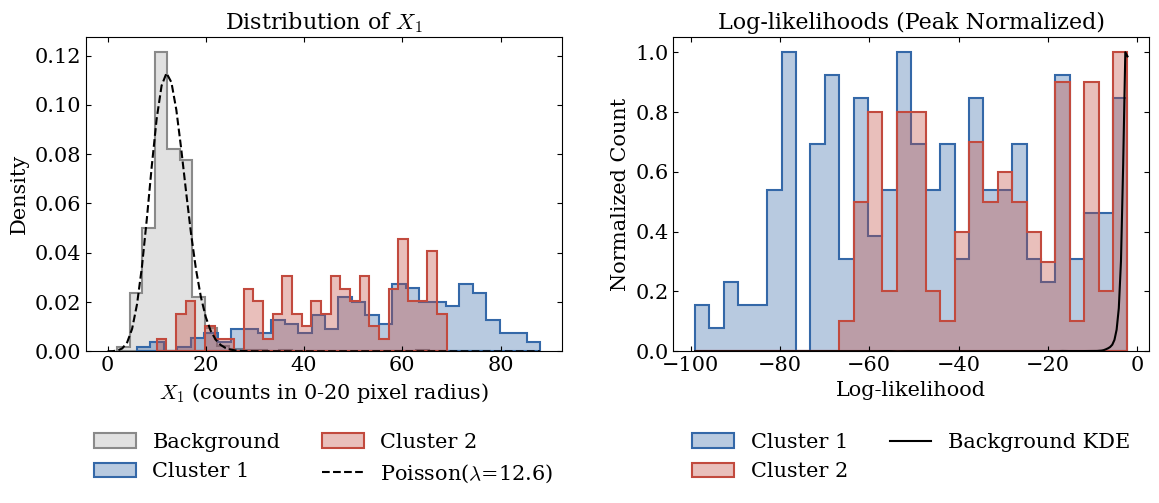

Mean N1 counts
Background = 12.9
Cluster 1 = 55.6
Cluster 2 = 46.2

Expected from density = 12.6


In [11]:
# Plot the distribution comparison
plt.figure(figsize=(12, 5.5))

# Left panel, histograms of N1 for the three groups
plt.subplot(1, 2, 1)
plt.hist(background_N1, bins=30, density=True, label='Background',  # Each group has its own 30 bins
         histtype='stepfilled', facecolor=('C5', 0.25), edgecolor='C5', linewidth=1.5)
plt.hist(cluster1_N1, bins=30, density=True, label='Cluster 1',
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
plt.hist(cluster2_N1, bins=30, density=True, label='Cluster 2',
         histtype='stepfilled', facecolor=('C3', 0.35), edgecolor='C3', linewidth=1.5)

# Add the theoretical Poisson distribution
# Expected count from the density (0.01 stars per pixel^2) and the radius of 20 pixels
x = np.arange(0, max(all_counts[:,0])+1)
lambda_expected = 0.01 * np.pi * 20**2
poisson = poisson_pmf(x, lambda_expected)
plt.plot(x, poisson, '--', color='k', label=f'Poisson($\\lambda$={lambda_expected:.1f})')

plt.xlabel('$X_1$ (counts in 0-20 pixel radius)')
plt.ylabel('Density')
plt.title('Distribution of $X_1$')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

# Right panel, log-likelihood of the counts
plt.subplot(1, 2, 2)
log_likelihoods = poisson_logpmf(all_counts[:,0], lambda_expected)

# Histograms of the log-likelihood of the clusters with the same bins
bins_ll = np.linspace(log_likelihoods.min(), log_likelihoods.max(), 31)
hist_c1, _ = np.histogram(log_likelihoods[10000:10200], bins=bins_ll)  # Cluster 1
hist_c2, _ = np.histogram(log_likelihoods[10200:], bins=bins_ll)  # Cluster 2

# Normalize each histogram by its peak value
hist_c1_norm = hist_c1 / np.max(hist_c1)
hist_c2_norm = hist_c2 / np.max(hist_c2)

# Plot the normalized histograms of the clusters
bin_centers = (bins_ll[:-1] + bins_ll[1:]) / 2
plt.hist(bin_centers, bins=bins_ll, weights=hist_c1_norm, label='Cluster 1',
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
plt.hist(bin_centers, bins=bins_ll, weights=hist_c2_norm, label='Cluster 2',
         histtype='stepfilled', facecolor=('C3', 0.35), edgecolor='C3', linewidth=1.5)

# The background is a smooth KDE, normalized by its peak value
background_ll = log_likelihoods[:10000]
x_kde = np.linspace(min(log_likelihoods), max(log_likelihoods), 200)

# One Gaussian kernel on every value, with the bandwidth of Scott's rule
bandwidth = background_ll.std(ddof=1) * len(background_ll) ** (-1 / 5)
scaled = (x_kde[:, None] - background_ll[None, :]) / bandwidth
kde_values = np.exp(-0.5 * scaled**2).sum(axis=1) / (len(background_ll) * bandwidth * np.sqrt(2 * np.pi))
plt.plot(x_kde, kde_values / kde_values.max(), '-', color='k', label='Background KDE')

plt.xlabel('Log-likelihood')
plt.ylabel('Normalized Count')
plt.title('Log-likelihoods (Peak Normalized)')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

plt.tight_layout()
plt.show()

# Print summary statistics
print("Mean N1 counts")
print(f"Background = {np.mean(background_N1):.1f}")
print(f"Cluster 1 = {np.mean(cluster1_N1):.1f}")
print(f"Cluster 2 = {np.mean(cluster2_N1):.1f}")
print(f"\nExpected from density = {lambda_expected:.1f}")

The comparison shows large differences between the background and the clusters. In the left panel, the background stars (gray) follow the expected Poisson distribution closely, as our random field model predicts. The stars in the clusters (blue and red) have far higher neighbor counts. Their mean counts are several times the background mean. This follows from the higher local density inside a cluster.

The right panel shows the distributions of the log-likelihood, each scaled to a peak of 1 because the groups differ in size. The clusters are histograms. The black line is a kernel density estimate (KDE) of the background log-likelihood. A histogram of the background would look spiky, because the log-likelihoods come from integer counts. The KDE smooths these values into a continuous density, which shows the overall shape better.

The log-likelihood separates the background from the clusters. Most cluster stars have log-likelihoods below $-10$, while the background stars lie mostly between $-2$ and $-4$. This suggests a detection algorithm that finds the regions where the local density gives an unusually low likelihood under the background model.

To see where the detection works, we create a spatial map of the log-likelihood over the field. We evaluate the likelihood on a grid of positions, which turns the point data into a continuous detection surface. Clusters appear in it as regions of extremely low likelihood.

In [12]:
# Settings of the map
grid_size = 50
radius = 20
lambda_bg = lambda_expected

# Grid of positions
x = np.linspace(0, field_size, grid_size)
y = np.linspace(0, field_size, grid_size)
X, Y = np.meshgrid(x, y)  # X and Y hold the coordinates of every grid point
likelihood = np.zeros((grid_size, grid_size))

# Calculate N1 and its log-likelihood at each grid point
for i in range(grid_size):
    for j in range(grid_size):
        # Distances from the grid point to all stars
        dx = field_with_clusters[:, 0] - X[i,j]
        dy = field_with_clusters[:, 1] - Y[i,j]

        # Wrap the separations at the boundaries
        dx = np.where(dx > field_size/2, dx - field_size, dx)
        dx = np.where(dx < -field_size/2, dx + field_size, dx)

        # The same for y
        dy = np.where(dy > field_size/2, dy - field_size, dy)
        dy = np.where(dy < -field_size/2, dy + field_size, dy)

        # Count the stars within the radius
        distances = np.sqrt(dx**2 + dy**2)
        N1 = np.sum(distances < radius)

        # Log-likelihood of the count under the Poisson distribution
        likelihood[i,j] = poisson_logpmf(N1, lambda_bg)

We plot the map of the log-likelihood.

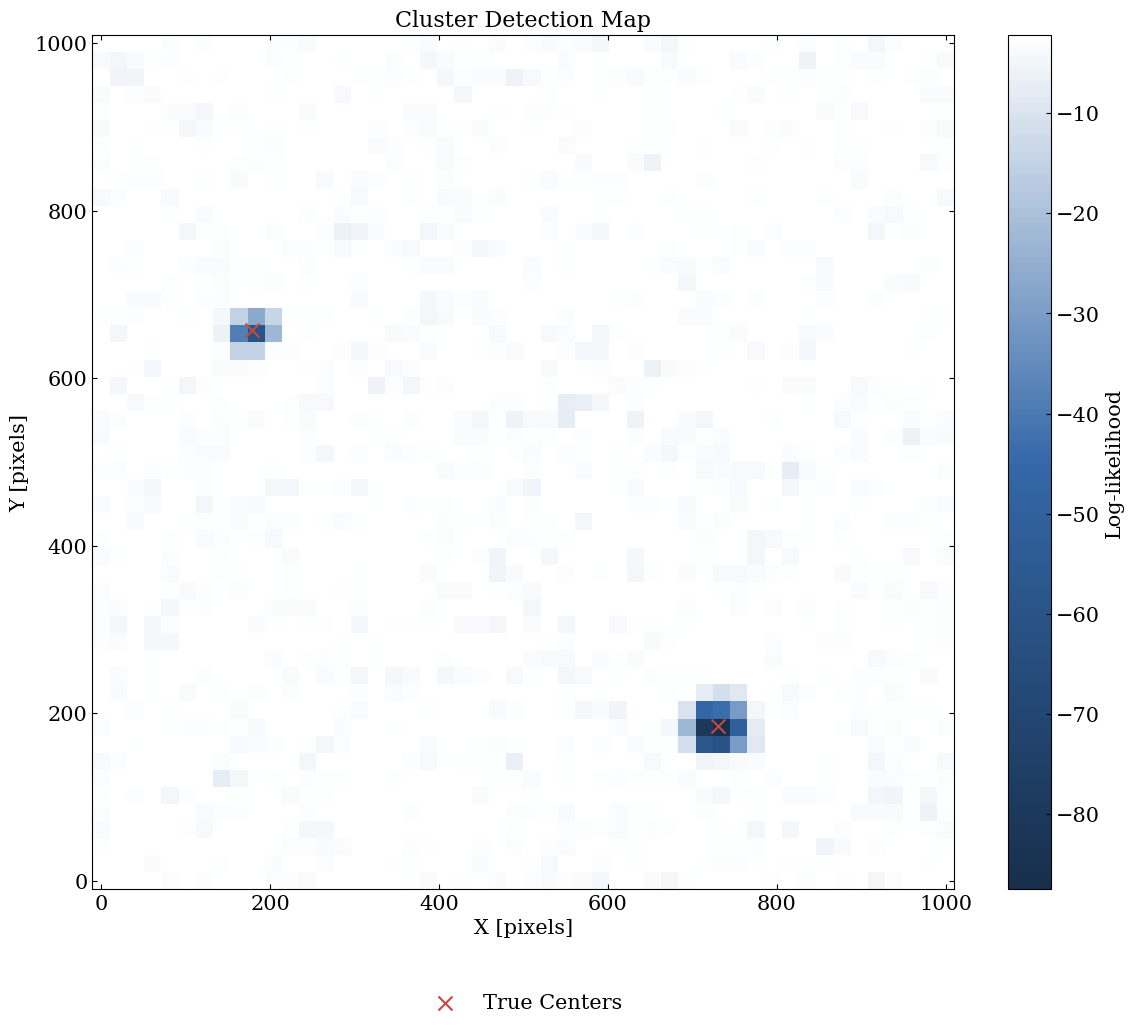

In [13]:
# Plot the map
plt.figure(figsize=(13.9, 11.1))
plt.pcolormesh(X, Y, likelihood, cmap=plt.colormaps['book_blue'].reversed())
plt.colorbar(label='Log-likelihood')
plt.scatter([center1[0], center2[0]], [center1[1], center2[1]],
            color='C3', marker='x', s=100, label='True Centers')

# Labels, title and legend
plt.xlabel('X [pixels]')
plt.ylabel('Y [pixels]')
plt.title('Cluster Detection Map')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.show()

The likelihood map shows both injected clusters as regions of extremely low likelihood, the dark regions of the map. The cluster locations stand out as clear minima, with values far below $-20$ against values between $-2$ and $-4$ for the background. This contrast shows that the Poisson likelihood detects overdensities well.

## Considerations on the Method

Our analysis so far relies on two simplifying choices. Both deserve a closer look.

**Choice of the Analysis Scale**

We chose a radius of 20 pixels for our neighbor counts, close to the size of our injected clusters. This prior knowledge helps the detection. In practice, we rarely know the cluster sizes in advance, so we need a multi-scale approach. Annuli are more useful than circles here.

- Annuli at different radii are statistically independent for a random field, so we can analyze each scale separately.
- Nested circles are correlated, because a larger circle contains all the stars of a smaller one.
- Real surveys often use a hierarchy of annuli to search for clusters over a range of physical scales.

**Poisson Distribution for the Background**

The Poisson distribution has three advantages for the background counts.

- The single parameter $\lambda$ has a clear physical meaning as the average count.
- The distribution models discrete counting data.
- For a uniform field, we can estimate $\lambda$ directly from the observed mean.

Real astronomical fields can have more complex statistics. The variance of real star counts can exceed their mean, for example when the background stars are themselves clustered. The negative binomial distribution can model such counts. Whether the simple Poisson model is enough depends on the astronomical context.

## Maximum Likelihood Estimation

So far we assumed that we know the true background parameter $\lambda$. In practice, we must estimate it from the data. Maximum likelihood estimation (MLE) is a principled way to find the parameter value that best explains our observations (Section 2.7).

The joint likelihood is the probability of observing all our data points together. For independent observations $x_1, \dots, x_N$ from a Poisson distribution, it is

$$\mathcal{L}(\lambda|x_1,\dots,x_N) = \prod_{i=1}^N \frac{\lambda^{x_i} e^{-\lambda}}{x_i!}.$$

Each factor is the probability of the count $x_i$ for the parameter $\lambda$. The product arises because we require all observations to occur together. The joint probability of independent events is the product of their probabilities.

The logarithm turns the product into a sum, which gives the log-likelihood

$$\ln \mathcal{L}(\lambda|x_1,\dots,x_N) = \sum_{i=1}^N (x_i \ln(\lambda) - \lambda - \ln(x_i!)).$$

The maximum likelihood estimate $\hat{\lambda}$ is the value that maximizes this function. For the Poisson distribution, we can find it analytically by setting the derivative to zero, which gives $\hat{\lambda} = \bar{x}$, the sample mean. Here we find it numerically instead, by computing the log-likelihood on a grid of $\lambda$ values. We apply it to the $X_1$ counts of the background stars in the field with clusters.

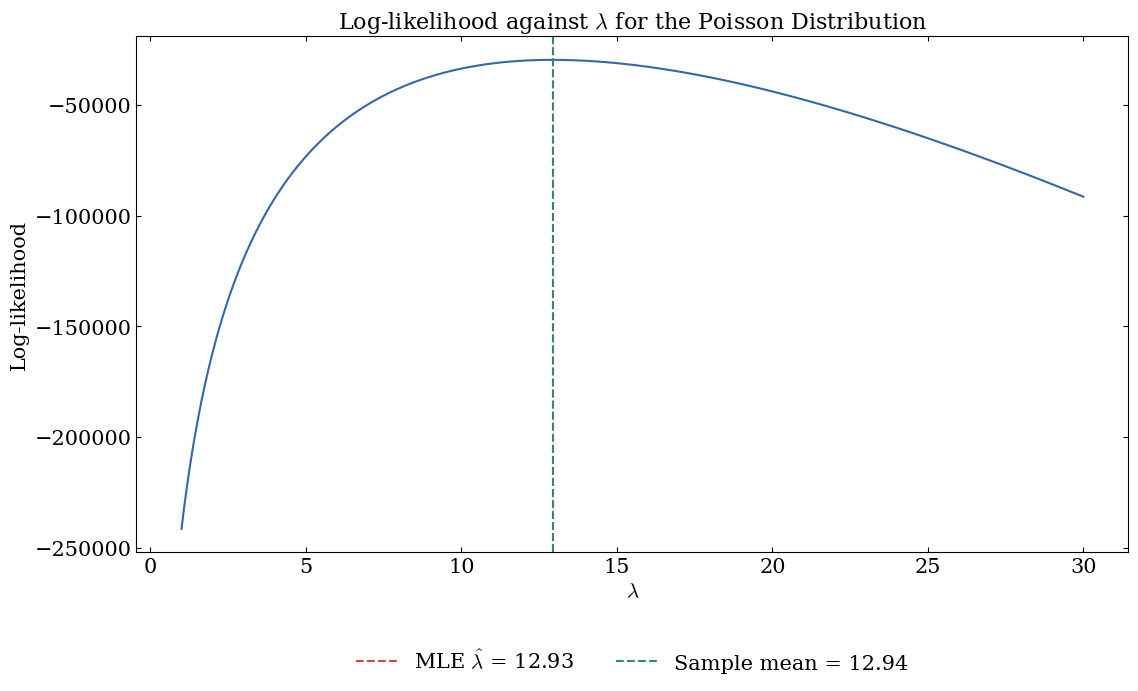

MLE estimate of lambda = 12.931
Sample mean = 12.938


In [14]:
# Use the counts of the background stars
counts_background = background_N1

# Grid of lambda values to search
lambda_grid = np.linspace(1, 30, 1000)
log_likelihoods = []

# Compute the log-likelihood for each lambda value
for lambda_val in lambda_grid:
    ll = np.sum(poisson_logpmf(counts_background, lambda_val))
    log_likelihoods.append(ll)

# Find the lambda with the highest log-likelihood
best_lambda = lambda_grid[np.argmax(log_likelihoods)]

# Plot the log-likelihood against lambda
plt.figure(figsize=(12.8, 6.7))
plt.plot(lambda_grid, log_likelihoods)

# Mark the MLE and the sample mean
plt.axvline(best_lambda, color='C3', linestyle='--',
            label=f'MLE $\\hat{{\\lambda}}$ = {best_lambda:.2f}')
plt.axvline(np.mean(counts_background), color='C2', linestyle='--',
            label=f'Sample mean = {np.mean(counts_background):.2f}')

# Labels and title
plt.xlabel('$\\lambda$')
plt.ylabel('Log-likelihood')
plt.title('Log-likelihood against $\\lambda$ for the Poisson Distribution')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

# Show the figure
plt.show()

# Print the optimal lambda and compare it with the sample mean
print(f"MLE estimate of lambda = {best_lambda:.3f}")
print(f"Sample mean = {np.mean(counts_background):.3f}")

The log-likelihood has a well-defined maximum that agrees with the sample mean. This confirms the theoretical result that the MLE of a Poisson distribution is the arithmetic mean of the observations. It also shows that our grid search works.

The grid search is simple, and it illustrates the general principle of maximum likelihood estimation. We evaluate the likelihood on a range of parameter values and select the value that makes our data most probable. For more complex distributions or models with several parameters, this brute-force approach becomes too expensive. This leads to the gradient-based optimization methods of later chapters.

From a Bayesian perspective, our MLE implicitly assumes a uniform prior over $\lambda$ (Section 2.7). We consider all parameter values equally plausible before we see the data. This uninformative prior is a conservative choice when we have no prior knowledge of the background density. When we have physical constraints or earlier observations, an informative prior can improve the estimate, in particular when the data are few.

## Summary

In this tutorial we used probability theory to detect structure in a spatial point pattern. Stellar cluster detection illustrates concepts that apply far beyond this one problem.

1. **Statistical modeling.** We built a null hypothesis from the Poisson distribution, which describes the expected behavior of randomly distributed stars.
2. **Likelihood-based detection.** We compared the observed neighbor counts with the expectation. The log-likelihood of a count is very low for most cluster stars, so it finds the overdensities.
3. **Parameter estimation.** Maximum likelihood estimation gave the expected count from the data. For a Poisson distribution it is the sample mean, and a grid search finds it as well.
4. **Spatial statistics.** The annuli showed how to handle a two-dimensional point pattern. Counts in non-overlapping annuli are independent for a random field, and periodic boundaries remove the edge effects.

The uniform Poisson background is an idealization. Real fields have density variations or clustering in the background, and a grid search becomes too expensive for models with many parameters. The same techniques apply to galaxy clusters in redshift surveys and to excess high-energy particle events. In each case, we measure what we expect under a null hypothesis and then identify the departures that signal real physical phenomena. A detection is therefore a statement about probability, and it depends on the background model.